# Joint-effect features with GRAANK

Compare attributes on their own (GIs) and together (GPs), then use the resulting
descriptors as classifier inputs. All feature tables below come from
`GRAANK.build_gradual_features`.

This notebook starts with a small example, shows one feature row per recording,
and finishes with the included rainfall and vegetation data.


## Set up

From the repository root, install this checkout and open the notebook:

```sh
python -m pip install -e .
python -m pip install jupyterlab ipykernel
python -m jupyterlab examples/joint_effect.ipynb
```

Choose that environment's kernel and run the cells in order. The setup below
also loads the local source when run from the repository root or `examples/`.
The real-data section uses the CSV files already included in `examples/datasets/`.


In [1]:
import sys
from pathlib import Path

repo_root = next(
    (
        root
        for root in (Path.cwd(), Path.cwd().parent)
        if (root / "src" / "so4gp").is_dir()
    ),
    None,
)
if repo_root is not None:
    sys.path.insert(0, str(repo_root / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from so4gp.algorithms import GRAANK

%matplotlib inline

## 1. Compare individual items with a joint pattern

Rows are six observations in order. Columns 0 and 1 are attributes A and B.
`0+` means A increases, `1-` means B decreases, and `0+ 1+` requires both
to increase between the same pair of observations.

A 2D input returns one row per pattern and six descriptor columns.


In [3]:
data = np.array(
    [
        [0, 4],
        [2, 5],
        [1, 2],
        [4, 3],
        [3, 0],
        [5, 1],
    ],
    dtype=float,
)

display(pd.DataFrame(data, columns=["A (column 0)", "B (column 1)"]))

items = GRAANK.build_gradual_features(data, pattern_level=1)
joint = GRAANK.build_gradual_features(data, pattern_level=2)
comparison = pd.concat([items.loc[["0+", "1+"]], joint.loc[["0+ 1+"]]])
display(comparison.round(3))

assert np.isclose(joint.loc["0+ 1+", "density"], 3 / 15)
assert joint.loc["0+ 1+", "connectivity"] == 3
assert joint.loc["0+ 1+", "avg_separation"] == 1
assert joint.loc["0+ 1+", "rank_dispersion"] == 0

,A (column 0),B (column 1)
0,0.0,4.0
1,2.0,5.0
2,1.0,2.0
3,4.0,3.0
4,3.0,0.0
5,5.0,1.0


descriptor,support,density,connectivity,avg_separation,rank_dispersion,singularity
pattern,,,,,,
0+,0.867,0.867,1.0,2.538,1.479,0.385
1+,0.800,0.200,3.0,1.000,0.000,0.333
0+ 1+,0.333,0.200,3.0,1.000,0.000,0.333


The joint pattern retains the forward pairs `(0, 1)`, `(2, 3)`, and `(4, 5)`.
They form three separate groups, all with a gap of one observation. Its
structural descriptors match `1+` here, because they retain the same pairs.

| Descriptor | Read it as |
| --- | --- |
| `support` | SO4GP's pair-support score; it can differ from density. |
| `density` | Fraction of forward observation pairs satisfying the pattern. |
| `connectivity` | Number of linked groups, including isolated readings. |
| `avg_separation` | Average gap in observation steps. |
| `rank_dispersion` | Variance of the gaps. |
| `singularity` | Largest fraction of pairs sharing one reading. |

An empty set has zero density and one component per observation. Undefined
statistics remain `NaN` in 2D tables. A smaller set or lower dispersion is not
automatically better for classification.


## 2. Choose pattern size and limit the work

`pattern_level=1` gives GIs. Higher levels give exactly that many attributes
per pattern. For two attributes there are two GP representatives:
`0+ 1+` and `0+ 1-`. Level 1 keeps both signs. Higher levels keep the lowest-numbered
participating column positive; reversing every sign gives the omitted counterpart.

A positive `max_patterns` cap takes a deterministic prefix. `None` includes
all combinations, including zero-support ones. The cap is not a support
threshold or a ranking by strength.


In [4]:
limited = GRAANK.build_gradual_features(data, pattern_level=2, max_patterns=1)
display(limited.round(3))
assert limited.index.tolist() == ["0+ 1+"]

descriptor,support,density,connectivity,avg_separation,rank_dispersion,singularity
pattern,,,,,,
0+ 1+,0.333,0.2,3.0,1.0,0.0,0.333


## 3. Turn recordings into classifier features

For a 3D array, the axes are `(recordings, observations, channels)`. Each
recording becomes **one row** with `(pattern, descriptor)` columns.

The synthetic labels below describe how the recordings were made: `same`
has two increasing channels; `opposite` has one increasing and one decreasing
channel. Labels are supplied separately; density is a feature, not a label.
Training and test recordings are separated before feature extraction.


In [5]:
same = np.array([[1, 1], [2, 2], [3, 3], [4, 4]], dtype=float)
opposite = np.array([[1, 4], [2, 3], [3, 2], [4, 1]], dtype=float)
train = np.stack([same, opposite, same + 0.2, opposite + 0.2])
test = np.stack([same + 1, opposite - 1])
y_train = np.array(["same", "opposite", "same", "opposite"])
y_test = np.array(["same", "opposite"])

x_train = GRAANK.build_gradual_features(train, pattern_level=2, max_patterns=2)
x_test = GRAANK.build_gradual_features(test, pattern_level=2, max_patterns=2)

print("Training features:", x_train.shape)
print("Test features:", x_test.shape)
density_view = x_train.xs("density", level="descriptor", axis=1).copy()
density_view["Known label"] = y_train
display(density_view)

assert x_train.shape == (4, 12)
assert x_train.columns.equals(x_test.columns)
assert np.isfinite(x_train.to_numpy()).all()

Training features: (4, 12)
Test features: (2, 12)


pattern,0+ 1+,0+ 1-,Known label
recording,,,
0,1.0,0.0,same
1,0.0,1.0,opposite
2,1.0,0.0,same
3,0.0,1.0,opposite


In [6]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=2000),
)
model.fit(x_train, y_train)
predicted = model.predict(x_test)
display(pd.DataFrame({"Known label": y_test, "Predicted label": predicted}))
np.testing.assert_array_equal(predicted, y_test)

,Known label,Predicted label
0,same,same
1,opposite,opposite


The scaler learns from training recordings only. In 3D features, undefined
empty-set statistics become zero; connectivity still counts isolated readings.
Use the same channel order, pattern level, and cap for training and test data.

This constructed example illustrates the workflow. Use held-out real
recordings for a performance evaluation.


## 4. Explore rainfall and vegetation data

The included files contain July observations for 2000-2022. Rainfall is
measured in mm; EVI is a vegetation index. Each file has four numerical
channels: NRB, KAK, MAK, and WAJ, in that column order.

Parse and sort the dates, then pass only the numerical values to the builder.
Rainfall and EVI are analyzed separately. Their row gaps count years in these
files; index gaps in irregularly sampled data need not represent equal times.


In [7]:
data_dir = None if repo_root is None else repo_root / "examples" / "datasets"
if data_dir is None or not (data_dir / "ke_rain_data_2k.csv").is_file():
    raise FileNotFoundError("Open the notebook from the repository root or examples/.")


def load_series(filename):
    frame = pd.read_csv(data_dir / filename)
    frame.columns = frame.columns.str.strip()
    dates = pd.to_datetime(frame.iloc[:, 0], format="%m-%Y", errors="raise")
    values = frame.iloc[:, 1:].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(values.to_numpy()).all():
        raise ValueError("Resolve missing or non-finite observations first.")
    values.index = pd.DatetimeIndex(dates, name="Date")
    if values.index.has_duplicates:
        raise ValueError("Resolve duplicate dates first.")
    return values.sort_index()


datasets = {
    "Rainfall": load_series("ke_rain_data_2k.csv"),
    "EVI": load_series("ke_evi_data_2k.csv"),
}
for name, frame in datasets.items():
    channels = dict(enumerate(frame.columns))
    print(f"{name}: {len(frame)} observations; channels {channels}")
    display(frame.head(3))

Rainfall: 23 observations; channels {0: 'NRB (mm)', 1: 'KAK (mm)', 2: 'MAK (mm)', 3: 'WAJ (mm)'}


,NRB (mm),KAK (mm),MAK (mm),WAJ (mm)
Date,,,,
2000-07-01,22.01000,526.8000,18.45,12.21999
2001-07-01,57.55001,539.0801,0.90,13.44000
2002-07-01,45.17000,349.2700,20.47,15.32000


EVI: 23 observations; channels {0: 'NRB (EVI)', 1: 'KAK (EVI)', 2: 'MAK (EVI)', 3: 'WAJ (EVI)'}


,NRB (EVI),KAK (EVI),MAK (EVI),WAJ (EVI)
Date,,,,
2000-07-01,0.094866,0.401556,0.160511,0.120766
2001-07-01,0.236884,0.417010,0.183184,0.152754
2002-07-01,0.243191,0.370047,0.206061,0.109228


In [8]:
selections = {
    "Rainfall": ("0+", "1+", "0+ 1+"),  # NRB+ and KAK+
    "EVI": ("1+", "2-", "1+ 2-"),  # KAK+ and MAK-
}
item_tables, joint_tables, comparison_tables = {}, {}, {}
for name, frame in datasets.items():
    values = frame.to_numpy(dtype=float)
    item_tables[name] = GRAANK.build_gradual_features(values, pattern_level=1)
    joint_tables[name] = GRAANK.build_gradual_features(values, pattern_level=2)
    first, second, pattern = selections[name]
    comparison_tables[name] = pd.concat(
        [
            item_tables[name].loc[[first, second]],
            joint_tables[name].loc[[pattern]],
        ]
    )
    print(name)
    display(comparison_tables[name].round(3))

Rainfall


descriptor,support,density,connectivity,avg_separation,rank_dispersion,singularity
pattern,,,,,,
0+,0.534,0.534,1.0,8.452,29.922,0.141
1+,0.617,0.617,1.0,8.763,30.989,0.141
0+ 1+,0.688,0.419,1.0,8.858,32.027,0.132


EVI


descriptor,support,density,connectivity,avg_separation,rank_dispersion,singularity
pattern,,,,,,
1+,0.660,0.340,1.0,6.256,18.237,0.174
2-,0.597,0.403,1.0,7.078,22.190,0.167
1+ 2-,0.636,0.190,2.0,5.979,20.437,0.229


Compare each descriptor on its own axis because the units differ. More
connected groups means a more fragmented set of relationships; it does
not by itself mean that a pattern is more predictive.


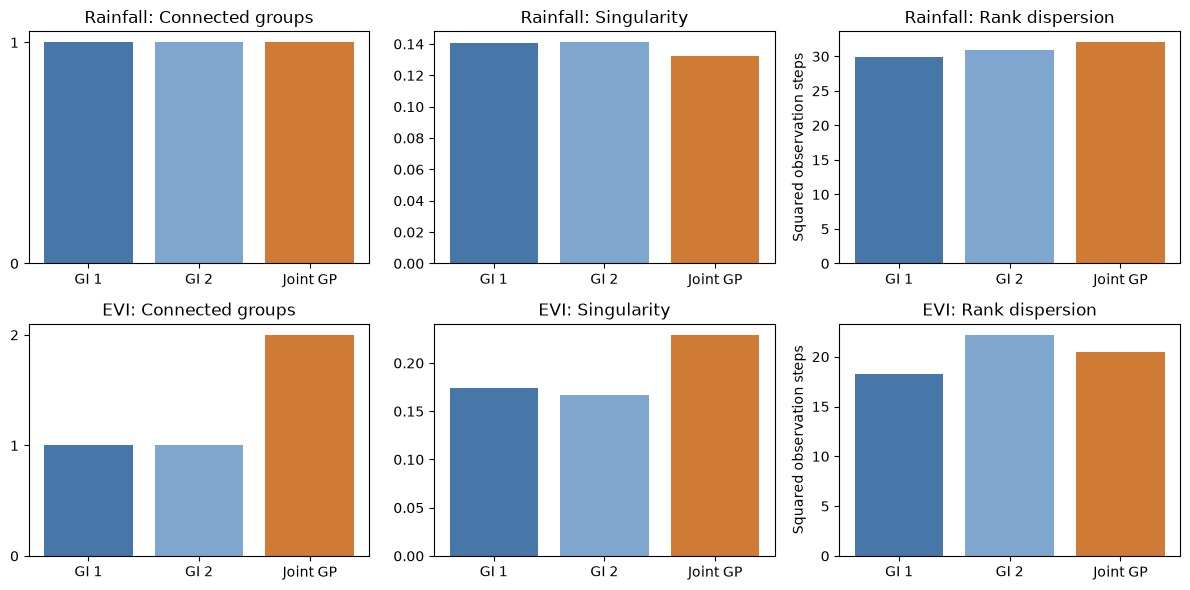

In [9]:
metrics = [
    ("connectivity", "Connected groups"),
    ("singularity", "Singularity"),
    ("rank_dispersion", "Rank dispersion"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), squeeze=False)
for row, (name, table) in enumerate(comparison_tables.items()):
    for ax, (metric, title) in zip(axes[row], metrics):
        ax.bar(
            ["GI 1", "GI 2", "Joint GP"],
            table[metric],
            color=["#4777A8", "#7EA6CE", "#D07B35"],
        )
        ax.set_title(f"{name}: {title}")
        ax.set_ylim(bottom=0)
        if metric == "connectivity":
            ax.set_yticks(range(int(table[metric].max()) + 1))
        elif metric == "rank_dispersion":
            ax.set_ylabel("Squared observation steps")
fig.tight_layout()
plt.show()

## 5. Extend the composition to three attributes

Build a three-item pattern with `pattern_level=3`. This example follows
rainfall columns 0, 1, and 2 (NRB, KAK, and MAK), all increasing.
Adding conditions can retain fewer forward pairs and split connected groups.


In [10]:
rain = datasets["Rainfall"].to_numpy(dtype=float)
triples = GRAANK.build_gradual_features(rain, pattern_level=3, max_patterns=1)
progression = pd.concat(
    [
        item_tables["Rainfall"].loc[["0+"]],
        joint_tables["Rainfall"].loc[["0+ 1+"]],
        triples.loc[["0+ 1+ 2+"]],
    ]
)
display(progression.round(3))
assert progression["density"].is_monotonic_decreasing
assert progression["connectivity"].is_monotonic_increasing

descriptor,support,density,connectivity,avg_separation,rank_dispersion,singularity
pattern,,,,,,
0+,0.534,0.534,1.0,8.452,29.922,0.141
0+ 1+,0.688,0.419,1.0,8.858,32.027,0.132
0+ 1+ 2+,0.375,0.273,1.0,8.826,26.694,0.203


## Use your own data

1. Order observations consistently and keep finite numerical channels.
2. Exclude dates and labels from the array passed to the builder.
3. Choose `pattern_level` and a pattern cap suited to the number of channels.
4. Compare individual and joint descriptors, or use 3D features with the
   original recording labels and a separate test set.

The descriptors summarize joint gradual behavior. They do not establish
causality, and changes in graph structure alone do not demonstrate better
classification.
